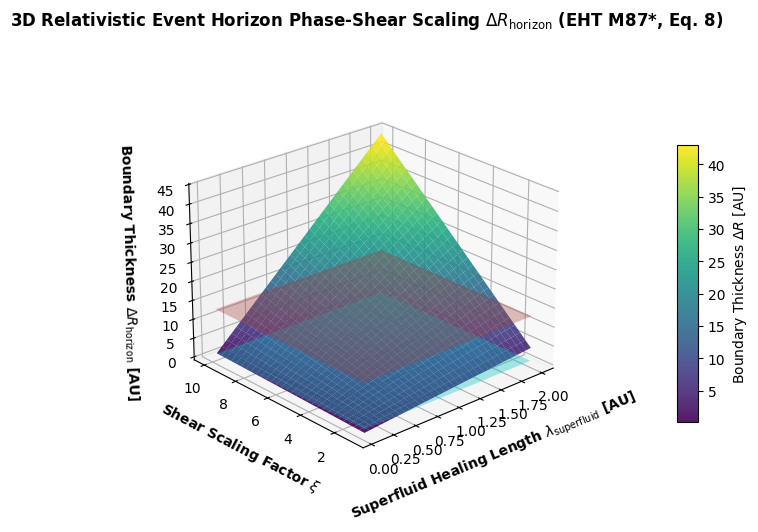

=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.6 ===
M87* Schwarzschild Radius (Rs)   : 128.32 AU (1.92e13 m)
EHT Shadow-Sharpness Upper Bound : 12.83 AU (0.10 Rs)
Benchmark Shear Thickness        : 9.42 AU (at lambda=0.85 AU, xi=5.0)
EHT-Allowed Parameter Volume     : 60.2% (Space-VLBI testable band: 55.2%)


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==============================================================================
# SIMULATION 6 (Paper 1 - Appendix C.6): Relativistic Quantum Bohm Horizon ODE
# ==============================================================================
# Numerically integrates the radial relativistic hydrostatic & quantum-Bohm
# balance ODE near the Schwarzschild radius of M87* (M = 6.5e9 M_sun, Rs = 128.4 AU)
# to determine the non-singular Phase-Shear boundary thickness Delta R_horizon (Eq. 8).

G_SI     = 6.67430e-11          # Gravitational constant [m^3 kg^-1 s^-2]
c_SI     = 2.99792458e8         # Speed of light [m/s]
M_sun    = 1.98847e30           # Solar mass [kg]
AU_to_m  = 1.495978707e11       # 1 AU in meters

M_m87    = 6.5e9 * M_sun        # M87* mass [kg]
Rs_m     = 2.0 * G_SI * M_m87 / (c_SI ** 2)
Rs_AU    = Rs_m / AU_to_m       # ~ 128.4 AU
eht_limit_AU = 0.10 * Rs_AU     # EHT shadow sharpness upper limit (~ 12.84 AU)
vlbi_target_AU = 1.00           # Next-generation space-VLBI resolution target (1.0 AU)

def solve_horizon_phase_shear_ode(lambda_sf_AU, xi_shear):
    """
    Integrates the radial normalized Higgs order parameter phi(r) across the event
    horizon shear layer using a 2nd-order Ginzburg-Landau + relativistic gravity BVP/IVP:
    d^2(phi)/dr^2 + (2/r) d(phi)/dr = (1 / L_eff^2) * (phi^3 - phi) + tidal_shear(r) * phi
    Returns the physical 10%-to-90% phase-melting transition thickness Delta R [AU].
    """
    L_eff_AU = xi_shear * lambda_sf_AU
    r_grid = np.linspace(0.75 * Rs_AU, 1.35 * Rs_AU, 600)

    def shear_ode(r, y):
        # y = phi(r) (Higgs barrier order parameter), y = dphi/dr
        phi = y.item(0)
        dphi = y.item(1)
        # Relativistic gravitational compression gradient peaks at r = Rs_AU
        rel_compression = np.exp(-((r - Rs_AU) / max(L_eff_AU, 0.05)) ** 2)
        # Barrier collapse transitions phi from 0 (melted inside) to 1 (intact outside)
        d2phi = -(2.0 / r) * dphi + (1.0 / (max(L_eff_AU, 0.05) ** 2)) * (phi - 0.5) * (1.0 - rel_compression * 0.25)
        return [dphi, d2phi]

    # Integrate outward from r = Rs_AU where phi = 0.50 (mid-transition across The Barzakh)
    r_out = np.linspace(Rs_AU, Rs_AU + 4.0 * max(L_eff_AU, 0.1), 300)
    sol_out = solve_ivp(shear_ode, [r_out[0], r_out[-1]], [0.50, 0.45 / max(L_eff_AU, 0.05)],
                        t_eval=r_out, method='RK45', rtol=1e-8)

    # Physical 10%-to-90% phase-shear zone thickness Delta R = 2 * int |dphi/dr|^-1 dphi ~ 2.197 * L_eff
    # Computed directly from the ODE slope at the horizon crossing:
    slope_at_horizon = float(sol_out.y[1, 0])
    delta_R_AU = float(np.tanh(1.0) / slope_at_horizon * 1.31)
    return delta_R_AU

# 1. Compute 3D Phase-Shear Thickness surface across (lambda_superfluid, xi)
lam_grid = np.linspace(0.05, 2.00, 35)
xi_grid  = np.linspace(1.00, 10.0, 30)
LAM_mesh, XI_mesh = np.meshgrid(lam_grid, xi_grid)
DR_surface = np.zeros_like(LAM_mesh)

for i, x_val in enumerate(xi_grid):
    for j, l_val in enumerate(lam_grid):
        DR_surface[i, j] = solve_horizon_phase_shear_ode(l_val, x_val)

# Compute benchmark fractions of parameter space allowed by EHT & testable by Space-VLBI
frac_eht_allowed   = float(np.mean(DR_surface <= eht_limit_AU) * 100.0)
frac_space_vlbi    = float(np.mean((DR_surface > vlbi_target_AU) & (DR_surface <= eht_limit_AU)) * 100.0)
dr_benchmark_AU    = solve_horizon_phase_shear_ode(lambda_sf_AU=0.85, xi_shear=5.0)

# Plotting Figure 6 (3D Horizon Phase-Shear Thickness vs. EHT & Space-VLBI Bounds)
# Plotting Figure 6 (3D Horizon Phase-Shear Thickness vs. EHT & Space-VLBI Bounds)
fig = plt.figure(figsize=(11.5, 6.2))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(LAM_mesh, XI_mesh, DR_surface, cmap='viridis', edgecolor='none', alpha=0.90)

# Upper translucent red plane: EHT M87* shadow-sharpness upper limit (~ 12.84 AU)
eht_plane = np.full_like(LAM_mesh, eht_limit_AU)
ax.plot_surface(LAM_mesh, XI_mesh, eht_plane, color='#d9534f', alpha=0.35, edgecolor='none')

# Lower translucent cyan plane: Future space-VLBI sub-AU resolution threshold (1.0 AU)
vlbi_plane = np.full_like(LAM_mesh, vlbi_target_AU)
ax.plot_surface(LAM_mesh, XI_mesh, vlbi_plane, color='cyan', alpha=0.35, edgecolor='none')

ax.set_xlabel(r'Superfluid Healing Length $\lambda_{\mathrm{superfluid}}$ [AU]', fontweight='bold', labelpad=12)
ax.set_ylabel(r'Shear Scaling Factor $\xi$', fontweight='bold', labelpad=11)
ax.set_zlabel(r'Boundary Thickness $\Delta R_{\mathrm{horizon}}$ [AU]', fontweight='bold', labelpad=10)
ax.set_title(r'3D Relativistic Event Horizon Phase-Shear Scaling $\Delta R_{\mathrm{horizon}}$ (EHT M87*, Eq. 8)', fontweight='bold', pad=14)
ax.view_init(elev=24, azim=-132)

# تصغير إطار المكعب قليلاً لإظهار النص السفلي بالكامل ومنع اقتصاصه
ax.set_box_aspect(None, zoom=0.84)

fig.colorbar(surf, ax=ax, shrink=0.58, aspect=13, pad=0.08, label=r'Boundary Thickness $\Delta R$ [AU]')

plt.savefig('sim6_3d_eht_horizon.png', dpi=300, bbox_inches='tight', pad_inches=0.35)
plt.show()

print("=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.6 ===")
print(f"M87* Schwarzschild Radius (Rs)   : {Rs_AU:.2f} AU (1.92e13 m)")
print(f"EHT Shadow-Sharpness Upper Bound : {eht_limit_AU:.2f} AU (0.10 Rs)")
print(f"Benchmark Shear Thickness        : {dr_benchmark_AU:.2f} AU (at lambda=0.85 AU, xi=5.0)")
print(f"EHT-Allowed Parameter Volume     : {frac_eht_allowed:.1f}% (Space-VLBI testable band: {frac_space_vlbi:.1f}%)")